In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# Load the wine quality dataset
df = pd.read_csv("winequality-red.csv")

# Display first five rows
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [8]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (1599, 12)

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   flo

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [9]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Number of Duplicate Rows:
240


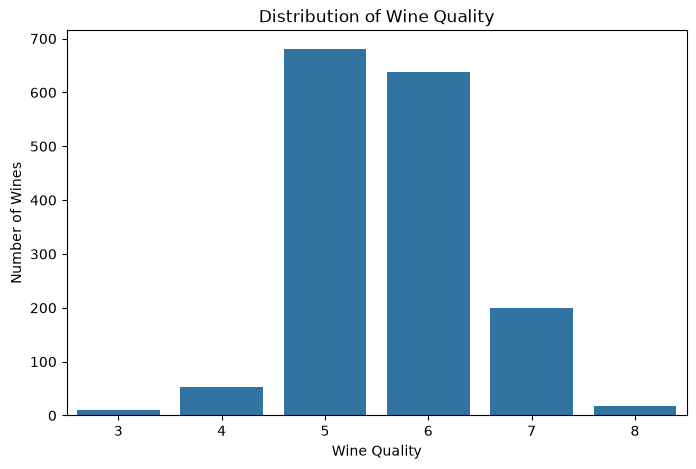

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='quality')

plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.show()

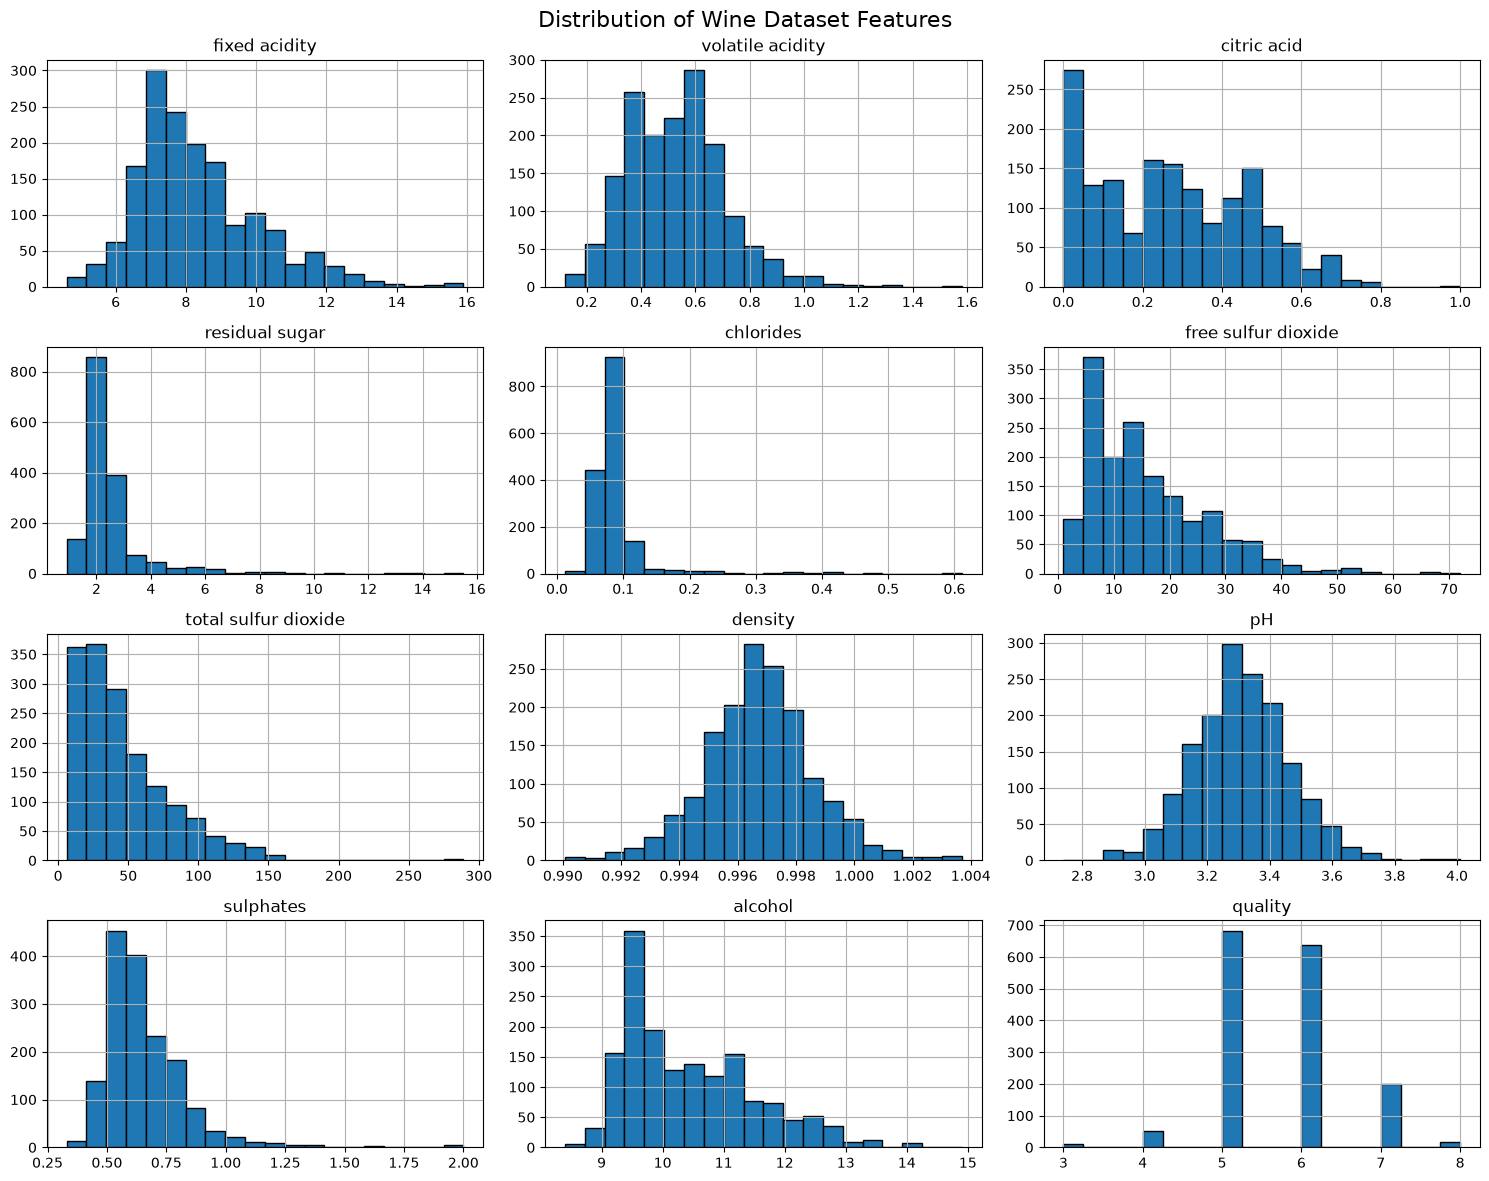

In [12]:
df.hist(figsize=(15, 12), bins=20, edgecolor='black')

plt.suptitle("Distribution of Wine Dataset Features", fontsize=16)

plt.tight_layout()
plt.show()

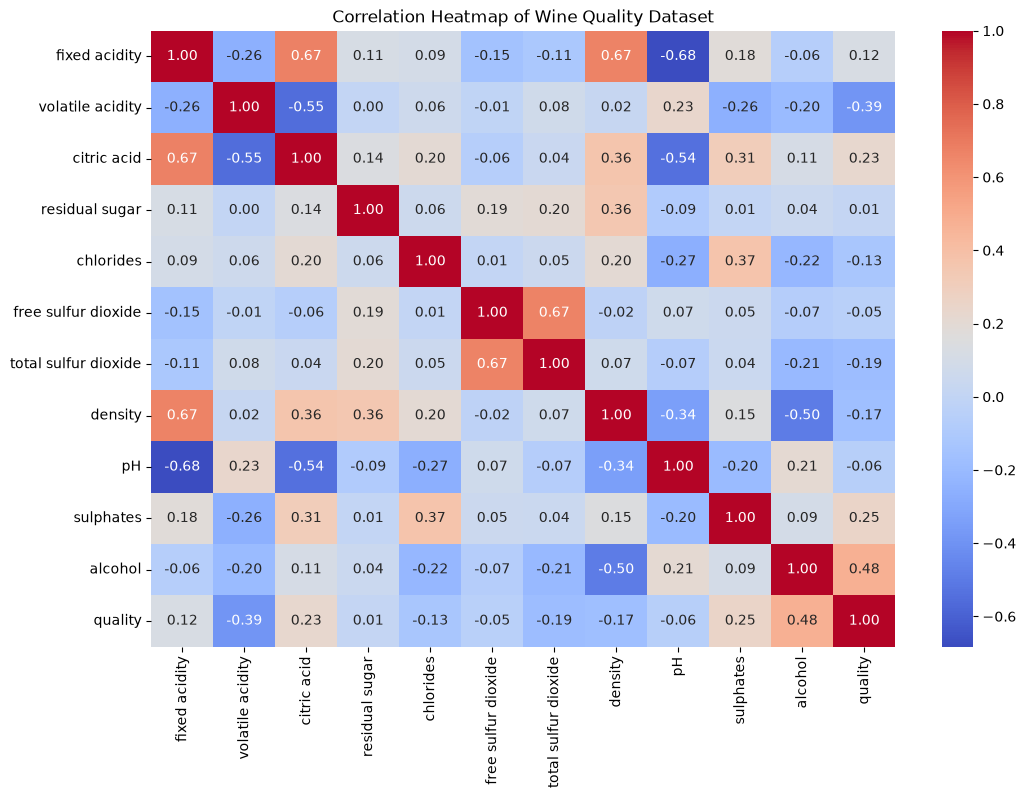

In [13]:
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Wine Quality Dataset")
plt.show()

In [14]:
# Check original dataset size
print("Before removing duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Check dataset size after cleaning
print("After removing duplicates:", df.shape)

# Verify duplicates
print("Remaining duplicates:", df.duplicated().sum())

Before removing duplicates: (1599, 12)
After removing duplicates: (1359, 12)
Remaining duplicates: 0


In [15]:
# Separate input features and target variable
X = df.drop('quality', axis=1)

y = df['quality']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (1359, 11)
Target Shape: (1359,)


In [16]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (1087, 11)
Testing Features: (272, 11)
Training Target: (1087,)
Testing Target: (272,)


In [17]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Data: (1087, 11)
Scaled Testing Data: (272, 11)


In [18]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [19]:
# Predict wine quality
y_pred = model.predict(X_test_scaled)

print("Actual Quality:")
print(y_test.values[:10])

print("\nPredicted Quality:")
print(y_pred[:10])

Actual Quality:
[5 6 5 8 6 5 7 4 7 6]

Predicted Quality:
[5 6 6 6 5 5 7 5 7 6]


Model Accuracy: 58.08823529411765 %

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       116
           6       0.53      0.60      0.56       107
           7       0.56      0.27      0.37        33
           8       0.00      0.00      0.00         3

    accuracy                           0.58       272
   macro avg       0.29      0.27      0.27       272
weighted avg       0.54      0.58      0.55       272



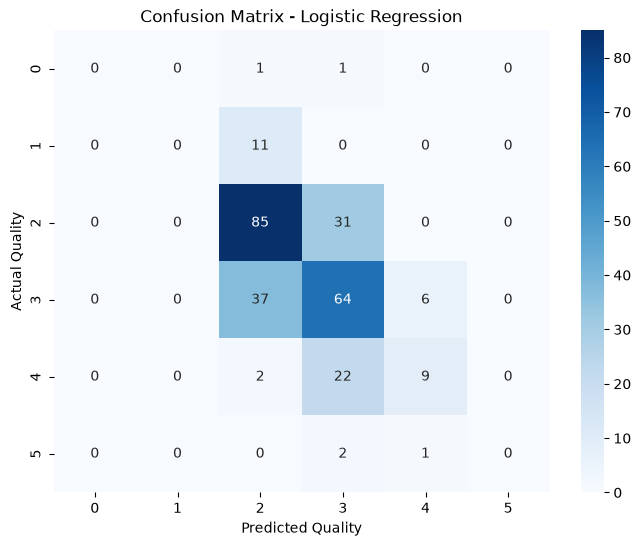

In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.show()

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 55.51470588235294 %


In [22]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 58.08823529411765 %


                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.580882     58.088235
1        Decision Tree  0.555147     55.514706
2        Random Forest  0.580882     58.088235


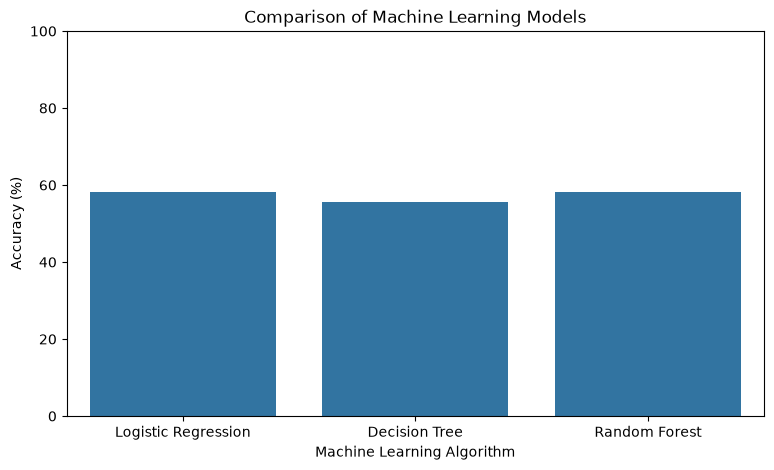

In [23]:
# Compare model performance
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        dt_accuracy,
        rf_accuracy
    ]
})

model_comparison['Accuracy (%)'] = (
    model_comparison['Accuracy'] * 100
)

print(model_comparison)

# Visualize comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy (%)'
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 100)
plt.show()

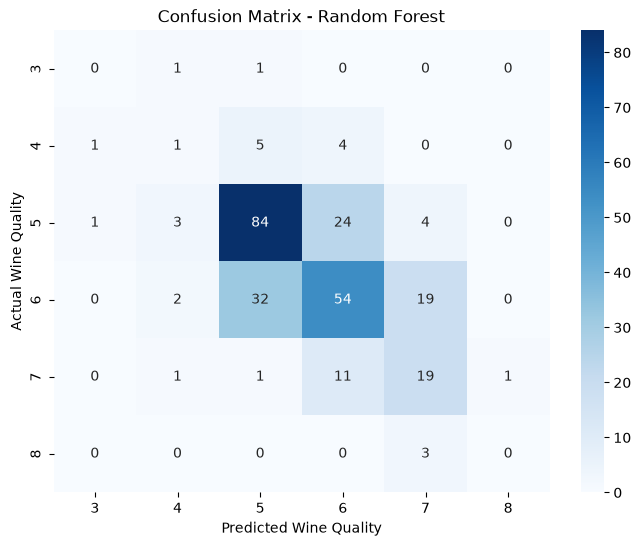

In [24]:
best_pred = rf_pred

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Wine Quality")
plt.ylabel("Actual Wine Quality")
plt.show()

In [25]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate classification reports
models = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

results = []

for name, predictions in models.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1-Score": report["macro avg"]["f1-score"],
        "Weighted F1-Score": report["weighted avg"]["f1-score"]
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(3))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,0.581,0.287,0.267,0.268,0.554
1,Decision Tree,0.555,0.270,0.276,0.271,0.541
2,Random Forest,0.581,0.302,0.316,0.306,0.576


                 Feature  Importance
10               alcohol    0.139804
9              sulphates    0.128846
1       volatile acidity    0.128454
7                density    0.088821
6   total sulfur dioxide    0.087679
2            citric acid    0.080089
4              chlorides    0.076210
8                     pH    0.075179
0          fixed acidity    0.068059
5    free sulfur dioxide    0.065333
3         residual sugar    0.061528


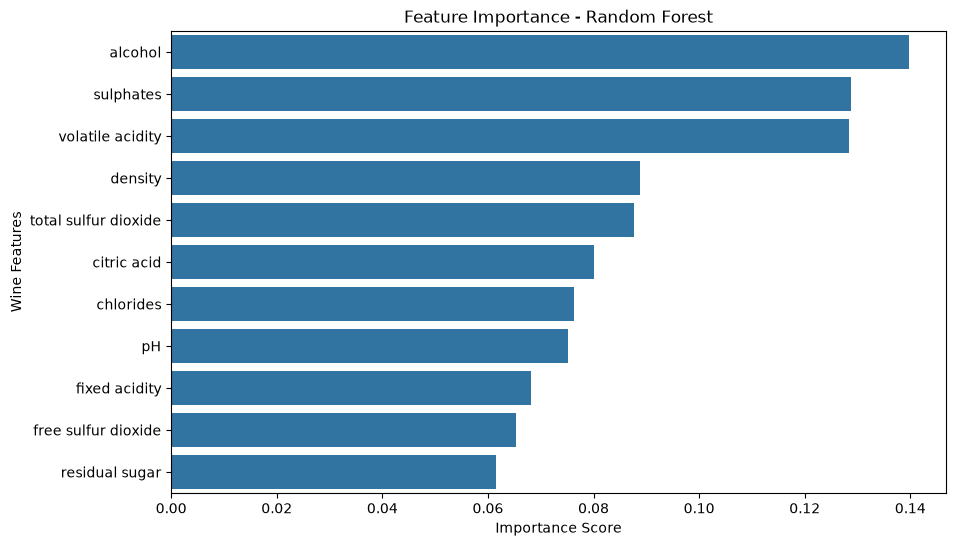

In [26]:
# Extract feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Wine Features")
plt.show()

In [37]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define parameter options
param_grid = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Create Random Forest model
rf = RandomForestClassifier(random_state=42)

# Perform randomized search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
)

# Train using training data only
random_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation F1 Score:")
print(random_search.best_score_)

Best Parameters:
{'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced'}

Best Cross Validation F1 Score:
0.3388374636051356


In [38]:
# Get the best model
best_model = random_search.best_estimator_

# Predict test data
tuned_pred = best_model.predict(X_test)

# Evaluate accuracy
from sklearn.metrics import accuracy_score, classification_report

tuned_accuracy = accuracy_score(y_test, tuned_pred)

print("Tuned Random Forest Accuracy:",
      tuned_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_pred,
    zero_division=0
))

Tuned Random Forest Accuracy: 54.04411764705882 %

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.25      0.45      0.32        11
           5       0.66      0.66      0.66       116
           6       0.57      0.40      0.47       107
           7       0.39      0.67      0.49        33
           8       0.00      0.00      0.00         3

    accuracy                           0.54       272
   macro avg       0.31      0.36      0.33       272
weighted avg       0.57      0.54      0.54       272



In [39]:
comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, tuned_pred)
    ],
    'Macro F1 Score': [
        0.306,
        __import__('sklearn.metrics', fromlist=['f1_score'])
        .f1_score(y_test, tuned_pred, average='macro')
    ]
})

display(comparison)

,Model,Accuracy,Macro F1 Score
0,Original Random Forest,0.580882,0.306000
1,Tuned Random Forest,0.540441,0.325547


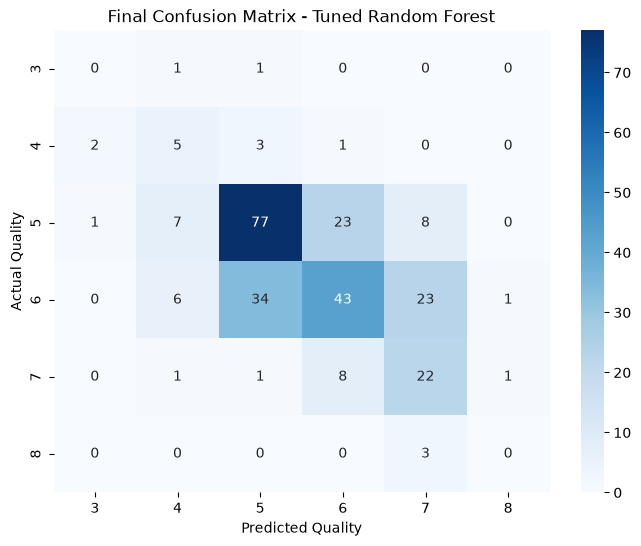

In [40]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    tuned_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Final Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")

plt.show()

In [41]:
# Create a sample wine
new_wine = pd.DataFrame([{
    'fixed acidity': 7.4,
    'volatile acidity': 0.70,
    'citric acid': 0.00,
    'residual sugar': 1.9,
    'chlorides': 0.076,
    'free sulfur dioxide': 11.0,
    'total sulfur dioxide': 34.0,
    'density': 0.9978,
    'pH': 3.51,
    'sulphates': 0.56,
    'alcohol': 9.4
}])

# Predict quality
prediction = best_model.predict(new_wine)

print("Predicted Wine Quality:", prediction[0])

Predicted Wine Quality: 5


In [42]:
import joblib
import os

# Save the trained model
joblib.dump(best_model, "wine_quality_model.pkl")

# Verify saved file
if os.path.exists("wine_quality_model.pkl"):
    print("Model saved successfully!")
    print("File size:", os.path.getsize("wine_quality_model.pkl"), "bytes")

Model saved successfully!
File size: 1895785 bytes


In [43]:
# Create prediction result
prediction_result = pd.DataFrame({
    'Actual Quality': y_test.values,
    'Predicted Quality': tuned_pred
})

# Save predictions
prediction_result.to_csv(
    "wine_quality_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!
